# Project 2, Milestone 3: Low-Rank Prediction with the SVD
MATH 344L: Applied Linear Algebra Lab, sample solution

In this notebook we use the SVD to find patterns in the user-movie rating matrix. Most ratings
are missing, so each model has to fill the gaps with a temporary guess before we can take an SVD.
We then compare three low-rank models with the baseline from Milestone 2.

We choose every setting (which model, which rank) using the validation set.
We use the test set only once, at the very end.

## Part A: Load project functions and data

In [1]:
import os
import subprocess
import sys

USER = "your-github-username"
REPO = "movie-recommender"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

Already up to date.


This copies our GitHub project into Colab, or updates it with git pull if
it is already there. Adding REPO/src to sys.path lets us import the functions we wrote in
Milestone 2 instead of pasting them in again.

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 81200 validation: 8832 test: 9968


This downloads MovieLens 100K (if needed) and loads the 100,000 ratings.
We split the data twice:
1. train / test: the test ratings are set aside for the final check.
2. fit / val: we build models on fit and compare them on val.

The fixed seeds give the same split every time. The ml-100k folder stays in Colab and is not committed.

## Part B: Set up a fair validation comparison

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

R_fit is the user-by-movie rating matrix built from the fit ratings only,
with NaN for missing ratings. Only about 5% of it is filled in, so how we handle the gaps
matters a lot.

val_u and val_i give the row and column of each validation rating (we subtract 1 because
MovieLens IDs start at 1 and Python starts at 0). score_at looks up our prediction for each of
those spots, keeps it between 1 and 5 stars, and computes the RMSE. Validation ratings never go
into R_fit, so they can't affect the model.

## Part C: Build the baseline prediction matrix

In [4]:
def baseline_matrix(R):
    """Full matrix: overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9731


The baseline predicts each rating as

overall average + user effect + movie effect

so it accounts for generous or harsh users and for popular or unpopular movies. Broadcasting
combines the user effects (a column) and movie effects (a row) into a full prediction matrix.
We use fit data only. This validation RMSE is the score every SVD model needs to beat.

## Part D: Create a rank-k helper

In [5]:
def rank_k(U, s, Vt, k):
    """Build a rank-k matrix from an already computed SVD."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

This keeps only the top k singular values and their singular vectors,
giving the best rank-k approximation of the matrix. We compute the SVD once and reuse it, so
trying many values of k is fast.

## Part E: Model 1 (fill gaps with movie averages)

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

The SVD needs a complete matrix, so Model 1 fills each missing rating with
that movie's average rating. Movies with no ratings in fit get the overall average.
np.where keeps the real ratings and fills only the gaps. Then we take the SVD of the filled
matrix F and use its rank-k version as our predicted ratings.

## Part F: Model 2 (let the SVD explain what the baseline misses)

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

The baseline already handles user and movie effects, so Model 2 only asks the
SVD to explain what is left over. For each known rating we store how far it is from the baseline
(for example, +1 means the user liked it more than expected). Missing entries get 0, meaning "no
information." To make predictions we add the SVD's rank-k result back to the baseline.

## Part G: Choose rank using validation RMSE

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    val_err1.append(score_at(P1, val_u, val_i, val_truth))
    val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, "validation RMSE:", min(val_err2))

Best Model 1 k: 15 validation RMSE: 0.9934477108911386
Best Model 2 k: 15 validation RMSE: 0.9492241710885614


For each rank k we build predictions from both models and score them on the
validation set. np.argmin finds the lowest error, and we pick the matching rank. Model 2 adds
B_fit back because its SVD part is just the leftover adjustment, not a full rating.

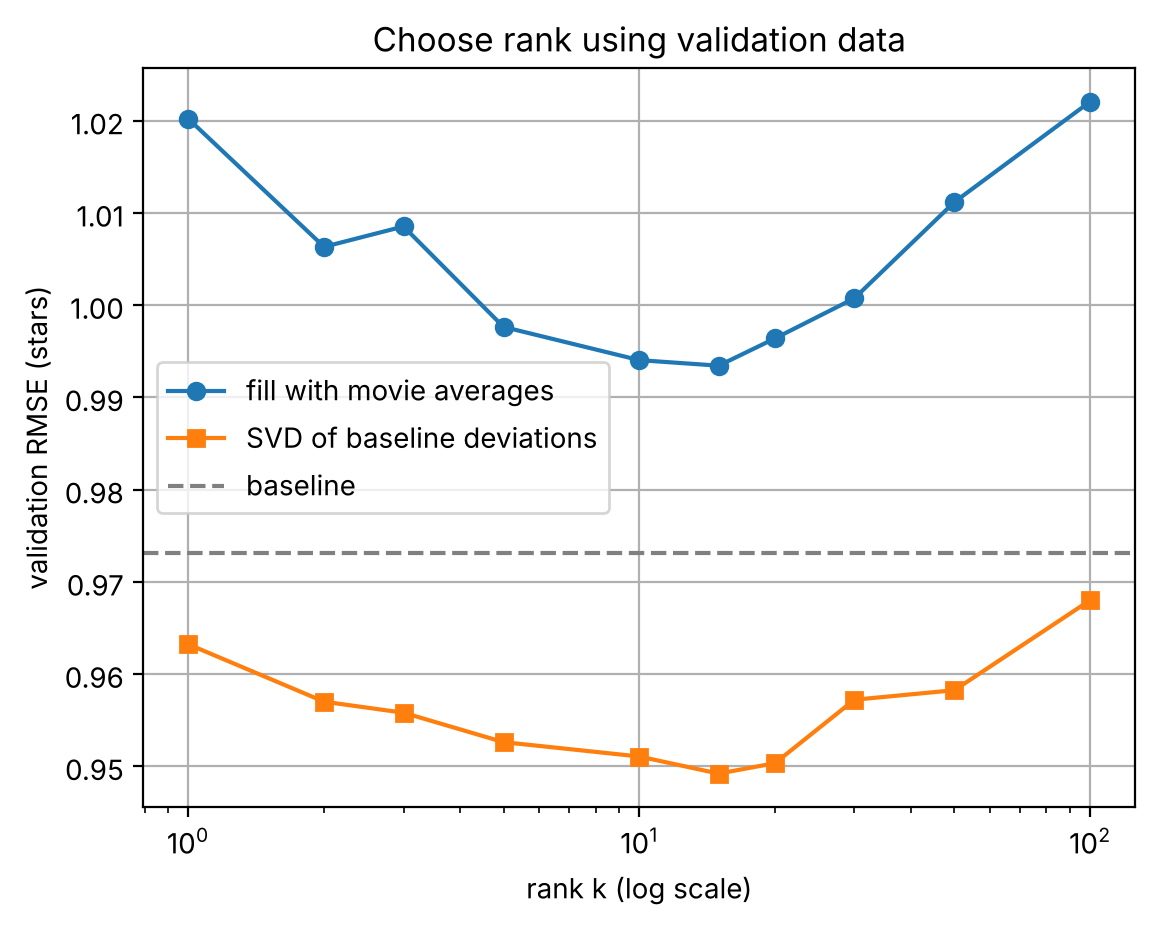

In [9]:
plt.semilogx(ks, val_err1, "o-", label="fill with movie averages")
plt.semilogx(ks, val_err2, "s-", label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--",
            label="baseline")
plt.xlabel("rank k (log scale)")
plt.ylabel("validation RMSE (stars)")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png", dpi=150)
plt.show()

This plots validation RMSE against rank. The dashed line is the baseline, and
anything below it is an improvement. Error first goes down as k grows (the model picks up real
patterns), then goes back up (the model starts fitting noise).

In [10]:
# save a copy of the figure in the repository's figures/ folder
import shutil
os.makedirs(f"{REPO}/figures", exist_ok=True)
_ = shutil.copy("validation_rmse_vs_k.png", f"{REPO}/figures/validation_rmse_vs_k.png")

This saves a copy of the figure in the repo's figures/ folder, where the assignment asks for it.

Model 2 beats the baseline at every rank. Its best is 0.9492 at k = 15,
compared with 0.9731 for the baseline. Model 1 never beats the baseline (best: 0.9934 at
k = 15). Filling the gaps with movie averages ignores whether a user rates high or low, and
since most of the matrix is filled-in values, the SVD mostly learns those averages back. Both
curves dip and then rise again as k gets large.

## Part H: Model 3 (iteratively improve the missing-value guesses)

In [11]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)

    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)

    return L + B

Model 2 filled every gap with 0 and stopped. Model 3 improves those guesses
by repeating three steps:
1. Take the rank-k SVD approximation.
2. Keep the real values at known entries and use the SVD's values in the gaps.
3. Repeat.

Each round gives better guesses for the gaps. Each round also needs a new SVD, so this model is slower.

In [12]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


We run Model 3 for 10 rounds at a few ranks and pick the rank with the lowest
validation RMSE.

Model 3 has the lowest validation RMSE: 0.9431 at k = 2, compared with 0.9492 for Model 2,
0.9934 for Model 1, and 0.9731 for the baseline. Based on validation, we choose Model 3 with k = 2.

## Part I: Refit and evaluate on the test set once

In [13]:
R_train = to_matrix(train)
test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = "iterative SVD"
elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = "baseline plus low-rank deviations"
else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)
    has_train = n_item_train > 0
    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
    F_train = np.where(known_train, R_train, means_train[None, :])
    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


We already chose the model and rank using validation. Now we refit that model
on all of train (fit + validation) for more data, keep the same rank, and score it once on the
test set next to the baseline. We don't change anything after seeing this result. Otherwise the
test set would no longer give an honest score.

The chosen model scores a test RMSE of 0.9286, compared with 0.9545 for
the baseline. That's about 0.03 stars (2.7%) better. The improvement we saw on validation also
shows up on the test set.

## Part J: Make a few recommendations

In [14]:
item_info = pd.read_csv(
    "ml-100k/u.item", sep="|", header=None, usecols=[0, 1],
    encoding="latin-1")
item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(title, "predicted rating:", round(predicted_scores[col], 2))

Great Day in Harlem, A (1994) predicted rating: 5.0
Aiqing wansui (1994) predicted rating: 5.0
Santa with Muscles (1996) predicted rating: 5.0
Saint of Fort Washington, The (1993) predicted rating: 5.0
Pulp Fiction (1994) predicted rating: 5.0


This loads the movie titles, takes user 1's row of predictions, keeps only
movies user 1 hasn't rated, and prints the 5 with the highest predicted ratings. We add 1 to each
column number to get the MovieLens movie ID.

All five of user 1's top picks hit the 5-star cap. Pulp Fiction (349 training ratings) makes
sense, but the other four (A Great Day in Harlem, Aiqing wansui, Santa with Muscles, and The Saint
of Fort Washington) have only 1 or 2 training ratings each
(Exercise 6 prints the counts). Our baseline takes each movie's
average at face value, so one 5-star rating gives a movie a very large movie effect, and that
pushes it to the top of the list. Shrinking the movie effect toward 0 for movies with few ratings,
or only recommending movies with some minimum number of ratings, would fix this. Either way,
these are predictions, not a guarantee user 1 will like them.

# Practice Exercises

### Exercise 1: Does filling matter?
For Model 1, we compare filling the gaps with the movie average, the overall average, and 3 stars
(plus 0 stars for the last part), using validation RMSE at a few ranks.

In [15]:
ks_check = [2, 5, 10, 20, 50]
fills = {
    "movie average": item_mean[None, :],
    "overall average": mu_fit,
    "3 stars": 3.0,
    "0 stars": 0.0,
}

fill_results = {}
for name, value in fills.items():
    F_try = np.where(known_fit, R_fit, value)
    U_t, s_t, Vt_t = np.linalg.svd(F_try, full_matrices=False)
    fill_results[name] = [score_at(rank_k(U_t, s_t, Vt_t, k), val_u, val_i, val_truth)
                          for k in ks_check]

fill_table = pd.DataFrame(fill_results, index=pd.Index(ks_check, name="rank k")).T
print("overall fit mean:", round(mu_fit, 3))
fill_table.round(4)

overall fit mean: 3.53


rank k,2,5,10,20,50
movie average,1.0063,0.9976,0.9940,0.9964,1.0112
overall average,1.0728,1.0568,1.0511,1.0545,1.0716
3 stars,1.1192,1.0856,1.0749,1.0788,1.1210
0 stars,2.4912,2.4036,2.3434,2.3508,2.4913


The movie average works best at every rank (best 0.9940). The overall average
gives about 1.05 to 1.07, and 3 stars gives about 1.07 to 1.12.

About 95% of the matrix is filled-in values, so the fill choice drives the SVD. Movie averages
already carry useful information (some movies really are better). A single constant treats every
unseen movie as the same, and 3 stars is lower than the typical rating (about 3.5), so it pulls
predictions down.

Filling with 0 is a bad idea (RMSE about 2.3 to 2.5). Zero isn't a valid rating, and it treats
"hasn't watched" as "hated it." The SVD ends up learning which movies people rated instead of how
they rated them, and about half of the predictions get clipped to 1 star. A missing rating means unknown, not bad.

Even the best fill doesn't beat the baseline (0.9731), which is why we try Model 2.

### Exercise 2: Understand the full-rank check

In [16]:
k_full = len(s2)                       # = min(943, 1682) = 943
L_full = rank_k(U2, s2, Vt2, k_full)
P2_full = L_full + B_fit
gaps = ~known_fit

print("full rank k =", k_full)
print("max |L_full - X_fit| (whole matrix):", np.abs(L_full - X_fit).max())
print("max |P2_full - B_fit| at the gaps:  ", np.abs(P2_full - B_fit)[gaps].max())
print("fit-set RMSE at known entries:      ", rmse(P2_full[known_fit], R_fit[known_fit]))
print("validation RMSE, full-rank Model 2: ", round(score_at(P2_full, val_u, val_i, val_truth), 4))
print("validation RMSE, baseline:          ", round(baseline_val_rmse, 4))

full rank k = 943
max |L_full - X_fit| (whole matrix): 2.0512237741687755e-14
max |P2_full - B_fit| at the gaps:   2.042810365310288e-14
fit-set RMSE at known entries:       1.4516630466826561e-15
validation RMSE, full-rank Model 2:  0.9731
validation RMSE, baseline:           0.9731


At full rank (all 943 singular values) we keep the entire SVD, so we get back exactly
the matrix we started with. The code confirms this (differences around 10^-14, just rounding).

That matrix has 0 in every gap, so the prediction in each gap is just the baseline + 0. All
validation ratings are in gaps, so the full-rank validation RMSE is exactly the baseline's (0.9731).

So the model didn't learn anything useful. It copies the training ratings perfectly (training
error about 0), but it has nothing new to say about unseen ratings. That's overfitting:
memorizing the data instead of finding patterns. The SVD only helps when we keep a small k,
which forces it to find a few shared patterns it can use to fill the gaps.

### Exercise 3: Study iteration
Model 3 with rank 5: validation RMSE after 1, 2, 5, and 10 imputation rounds.

In [17]:
def iterative_history(R, k, record_rounds):
    """Same steps as iterative_svd_predict, but records the validation
    RMSE after each requested round instead of rerunning from scratch."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)
    history = {}
    for r in range(1, max(record_rounds) + 1):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)
        if r in record_rounds:
            history[r] = score_at(L + B, val_u, val_i, val_truth)
    return history

rounds = [1, 2, 5, 10]
hist5 = iterative_history(R_fit, 5, rounds)

for r in rounds:
    print(f"rank 5, {r:2d} rounds: validation RMSE = {hist5[r]:.4f}")

rank 5,  1 rounds: validation RMSE = 0.9526
rank 5,  2 rounds: validation RMSE = 0.9456
rank 5,  5 rounds: validation RMSE = 0.9411
rank 5, 10 rounds: validation RMSE = 0.9433


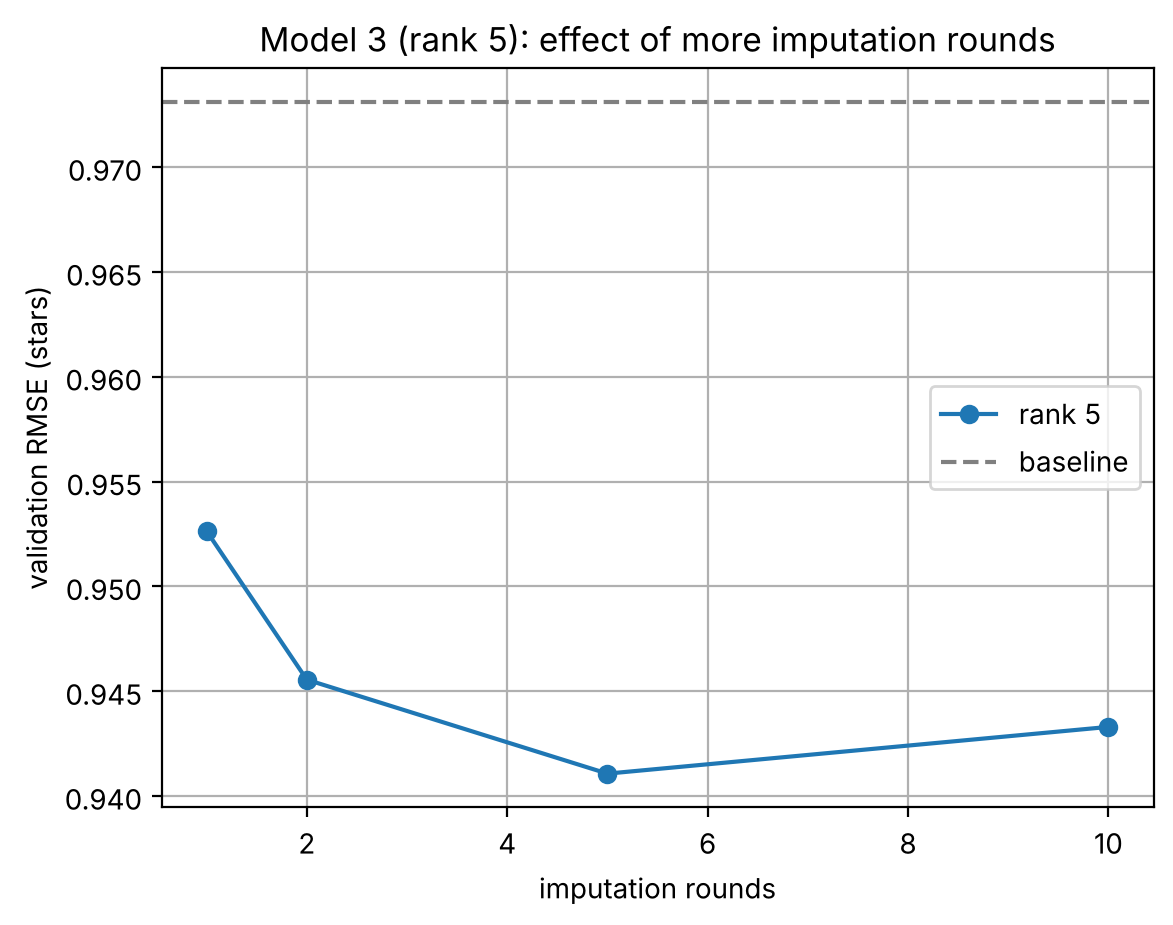

In [18]:
plt.plot(rounds, [hist5[r] for r in rounds], "o-", label="rank 5")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--", label="baseline")
plt.xlabel("imputation rounds")
plt.ylabel("validation RMSE (stars)")
plt.title("Model 3 (rank 5): effect of more imputation rounds")
plt.grid()
plt.legend()
plt.show()

At rank 5, the validation RMSE was 0.9526 after 1 round, 0.9456 after 2, 0.9411 after 5, and 0.9433 after 10.

One round is the same as Model 2 (it matches Model 2 at k = 5 in the Exercise 4 table). More
rounds help at first, with the best result at 5 rounds, but more iteration doesn't always help:
by 10 rounds the error has gone back up.

Why: the zeros in the gaps keep predictions close to the baseline, which acts as a safety net.
Each round replaces those zeros with the model's own guesses and then fits them as if they were
real data. A few rounds help, but too many let the model chase noise. So the number of rounds is
another setting to choose with validation, just like k.

### Exercise 4: Check for overfitting

In [19]:
# Training (fit-set) error vs validation error for Model 2 across ranks
train_err2 = []
for k in ks:
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    train_err2.append(rmse(np.clip(P2[known_fit], 1, 5), R_fit[known_fit]))

overfit_table = pd.DataFrame({"rank k": ks,
                              "Model 2 fit-set RMSE": np.round(train_err2, 4),
                              "Model 2 validation RMSE": np.round(val_err2, 4)}).set_index("rank k")

chosen_val = {"iterative SVD": min(val_err3),
              "baseline plus low-rank deviations": min(val_err2),
              "SVD of movie-average-filled matrix": min(val_err1)}[chosen_model]
print("Chosen model:", chosen_model)
print("its best validation RMSE:", round(chosen_val, 4))
print("its single test RMSE:    ", round(test_rmse, 4))
overfit_table

Chosen model: iterative SVD
its best validation RMSE: 0.9431
its single test RMSE:     0.9286


,Model 2 fit-set RMSE,Model 2 validation RMSE
rank k,,
1,0.9099,0.9632
2,0.8978,0.9570
3,0.8893,0.9558
5,0.8734,0.9526
10,0.8428,0.9511
15,0.8163,0.9492
20,0.7916,0.9504
30,0.7473,0.9572
50,0.6712,0.9583


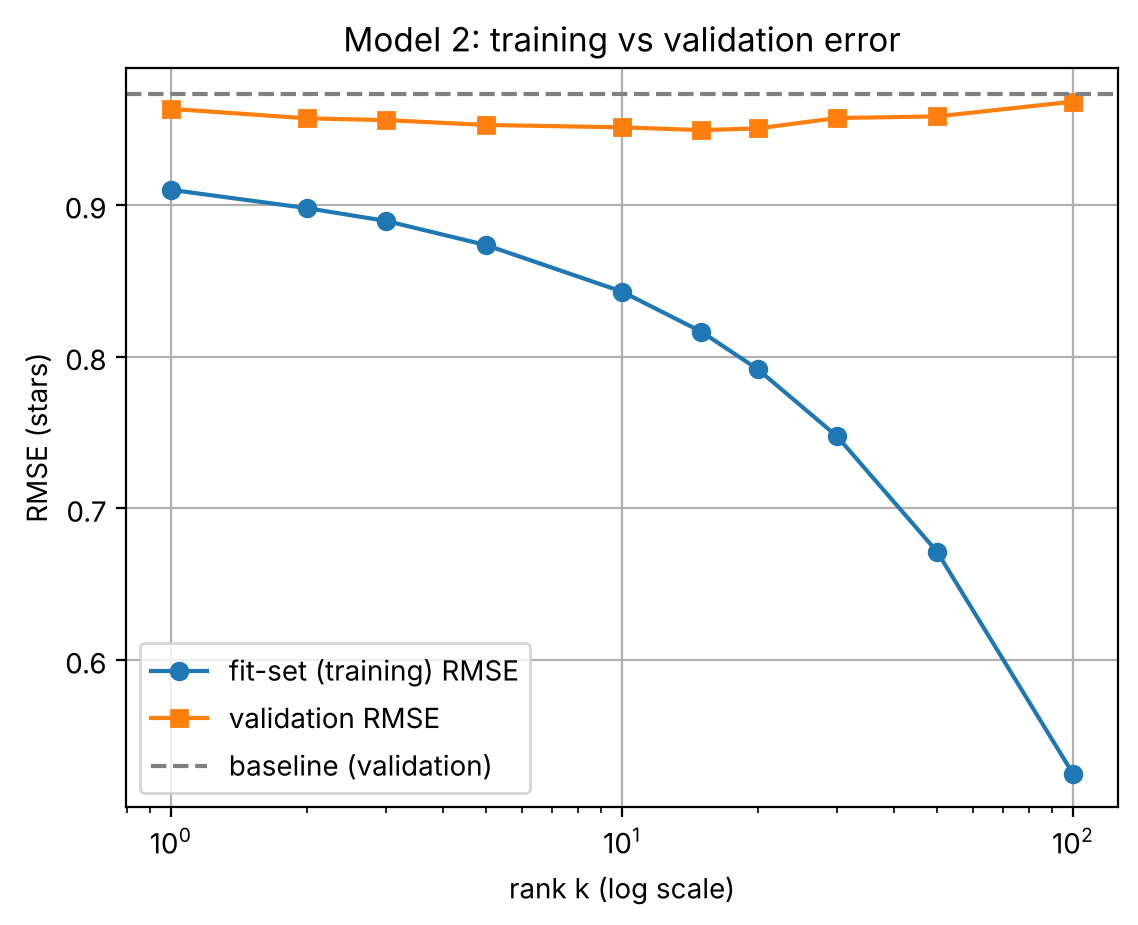

In [20]:
plt.semilogx(ks, train_err2, "o-", label="fit-set (training) RMSE")
plt.semilogx(ks, val_err2, "s-", label="validation RMSE")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--", label="baseline (validation)")
plt.xlabel("rank k (log scale)")
plt.ylabel("RMSE (stars)")
plt.title("Model 2: training vs validation error")
plt.grid()
plt.legend()
plt.show()

For Model 2, training error keeps dropping as k grows (0.910 at k = 1 down to
0.525 at k = 100), because more components can match the training ratings more closely.
Validation error is lowest at k = 15 (0.9492) and then rises (0.9680 at k = 100). The growing
gap between the two is overfitting: the extra components fit noise, not real patterns.

The chosen model's validation RMSE was 0.9431 and its test RMSE is 0.9286, which is close. The
test score is slightly better because the final model was trained on more data (about 90,000 vs.
81,000 ratings); the baseline improved too, from 0.9731 to 0.9545.

Why choose the rank first? If we picked k based on test scores, we'd partly be picking
whatever got lucky on those specific test ratings, and the test score would look better than it
really is. Choosing on validation keeps the test set untouched, so its score is an honest estimate.

### Exercise 5: Cold-start limitation
We add a new user with no ratings and refit the chosen model to see what it predicts.

In [21]:
R_new = np.vstack([R_train, np.full((1, R_train.shape[1]), np.nan)])
new_row = R_new.shape[0] - 1

if chosen_model == "iterative SVD":
    P_new = iterative_svd_predict(R_new, best_k3, n_iter=10)
else:
    B_new = baseline_matrix(R_new)
    X_new = np.where(~np.isnan(R_new), R_new - B_new, 0.0)
    U_n, s_n, Vt_n = np.linalg.svd(X_new, full_matrices=False)
    P_new = rank_k(U_n, s_n, Vt_n, best_k2) + B_new

mu_n, bu_n, bi_n = bias_baseline(R_new)
print("new user's b_u:", bu_n[new_row])
print("NaN predictions for the new user:", np.isnan(P_new[new_row]).sum(), "of", R_new.shape[1])

# fallback: treat the new user's effect as 0, so the prediction is overall mean + movie effect
fallback = mu_n + bi_n
n_train = (~np.isnan(R_train)).sum(axis=0)

print("\nFallback top 5 (all movies):")
for col in np.argsort(fallback)[-5:][::-1]:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(f"  {title:40s} predicted {np.clip(fallback[col], 1, 5):.2f}   training ratings: {n_train[col]}")

print("\nFallback top 5 (movies with at least 20 training ratings):")
popular = np.where(n_train >= 20)[0]
for col in popular[np.argsort(fallback[popular])[-5:][::-1]]:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(f"  {title:40s} predicted {np.clip(fallback[col], 1, 5):.2f}   training ratings: {n_train[col]}")

/home/claude/srun/movie-recommender/src/models.py:11: RuntimeWarning: Mean of empty slice
  b_user = np.nanmean(R - mu, axis=1)


new user's b_u: nan
NaN predictions for the new user: 1682 of 1682

Fallback top 5 (all movies):
  Great Day in Harlem, A (1994)            predicted 5.00   training ratings: 1
  Aiqing wansui (1994)                     predicted 5.00   training ratings: 1
  Santa with Muscles (1996)                predicted 5.00   training ratings: 2
  Saint of Fort Washington, The (1993)     predicted 4.99   training ratings: 2
  Someone Else's America (1995)            predicted 4.90   training ratings: 1

Fallback top 5 (movies with at least 20 training ratings):
  Close Shave, A (1995)                    predicted 4.44   training ratings: 102
  Schindler's List (1993)                  predicted 4.36   training ratings: 270
  Wrong Trousers, The (1993)               predicted 4.35   training ratings: 107
  Wallace & Gromit: The Best of Aardman Animation (1996) predicted 4.34   training ratings: 59
  Shawshank Redemption, The (1994)         predicted 4.34   training ratings: 251


With our baseline, a new user gets no predictions at all. Their user effect is the average of
their ratings, and with no ratings that average is undefined (NaN, with a "Mean of empty slice"
warning). The NaN carries into every prediction in their row, so the model can't rank anything
for them.

The simplest fix is to set a new user's effect to 0, so their prediction is just overall average
+ movie effect. The SVD adds nothing for them, since their row has no ratings to learn from. So
every new user gets the same list, and it isn't personalized. With our baseline, that list is
made of movies with only one or two ratings, because a single 5-star rating gives a movie a huge
movie effect. Only counting movies with at least 20 ratings gives a much more sensible default
(well-known, well-liked films).

What would help:
- Ask for a few ratings at sign-up, such as having them rate 10 popular movies.
- User info like age, gender, and occupation (MovieLens has these in u.user).
- Movie info like genre (in u.item), so we can suggest movies similar to what they like.
- Behavior data like clicks, searches, and watch time.

### Exercise 6: Explain the result

In [22]:
final = pd.DataFrame({
    "": ["Baseline", f"Chosen: {chosen_model} (k={ {'iterative SVD': best_k3, 'baseline plus low-rank deviations': best_k2}.get(chosen_model, best_k1) })"],
    "validation RMSE": [round(baseline_val_rmse, 4), round(chosen_val, 4)],
    "test RMSE": [round(test_baseline, 4), round(test_rmse, 4)],
}).set_index("")
print("improvement on test:", round(test_baseline - test_rmse, 4), "stars",
      f"({100 * (test_baseline - test_rmse) / test_baseline:.1f}%)")

# how many training ratings did each of user 1's recommended movies have?
n_train = (~np.isnan(R_train)).sum(axis=0)
mu_t, b_user_t, b_item_t = bias_baseline(R_train)
print("\nUser 1's recommendations:")
for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(f"  {title:40s} training ratings: {n_train[col]:4d}   movie effect: {b_item_t[col]:+.2f}")

final

improvement on test: 0.0259 stars (2.7%)

User 1's recommendations:
  Great Day in Harlem, A (1994)            training ratings:    1   movie effect: +1.90
  Aiqing wansui (1994)                     training ratings:    1   movie effect: +1.74
  Santa with Muscles (1996)                training ratings:    2   movie effect: +1.49
  Saint of Fort Washington, The (1993)     training ratings:    2   movie effect: +1.46
  Pulp Fiction (1994)                      training ratings:  349   movie effect: +0.47


,validation RMSE,test RMSE
,,
Baseline,0.9731,0.9545
Chosen: iterative SVD (k=2),0.9431,0.9286


The baseline test RMSE of 0.9545 means that predicting with the overall average plus user and
movie effects is off by just under one star on a typical rating. Our chosen model, iterative SVD
with rank 2, scores 0.9286, about 0.03 stars (2.7%) better. We picked it using validation and
checked the test set once, so this is a fair comparison. The gain is real but small, since most of
what predicts a rating is already in "how generous is this user" and "how good is this movie."

The recommendations for user 1 show the limits of RMSE. Four of the five picks are obscure movies
with only one or two ratings, pushed to the top by their movie effects. A model can have a good
average error and still make odd top-5 lists, because RMSE measures accuracy over many ratings,
not how good one person's recommendations are. The recommendations also don't prove user 1 would
enjoy them, and they don't account for variety or movies the user has seen elsewhere.

### Before moving on (checklist)
- Added baseline_matrix, rank_k, and iterative_svd_predict to src/models.py
  (score_at stays in the notebook because it depends on which data split we're scoring).
- Saved validation_rmse_vs_k.png in figures/.
- Ran Runtime → Restart and run all, and every cell runs.
- Saved to GitHub as notebooks/03_low_rank.ipynb with the commit message
  "Milestone 3: low-rank movie recommendations".
- Did not commit ml-100k/ (it's in .gitignore).